Instagram Analytics

Import numpy and pandas & load data 

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
df = pd.read_csv("/Rezilyen intern/Data set/Instagram_Analytics.csv")
print("Shape:", df.shape)
df.head()

Shape: (29999, 23)


,post_id,account_id,account_type,follower_count,media_type,content_category,traffic_source,has_call_to_action,post_datetime,post_date,...,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,performance_bucket_label
0,IG0000001,7,brand,3551,reel,Technology,Home Feed,1,2024-11-30 06:00:00,2024-11-30,...,5,7,34,4327,6230,0.0385,899,100,7,medium
1,IG0000002,20,creator,31095,image,Fitness,Hashtags,1,2025-08-15 15:00:00,2025-08-15,...,10,21,68,7451,8268,0.0663,805,122,5,viral
2,IG0000003,15,brand,8167,reel,Beauty,Reels Feed,0,2025-09-11 16:00:00,2025-09-11,...,2,1,22,1639,2616,0.0531,758,115,8,high
3,IG0000004,11,creator,9044,carousel,Music,External,0,2025-09-18 03:00:00,2025-09-18,...,0,7,0,2877,3171,0.0309,402,115,7,medium
4,IG0000005,8,creator,15986,reel,Technology,Profile,0,2025-03-21 09:00:00,2025-03-21,...,8,5,21,5350,8503,0.0221,155,112,9,low


Data handling and missing values

In [19]:
# 1. Check null values
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

In [20]:
# Check total null values in the entire dataset
print("Total Null Values:", df.isnull().sum().sum())

Total Null Values: 0


EDA: Mean, Median, Mode and Standard Deviation of Likes

In [21]:
# EDA: Mean, Median, Mode, Standard Deviation on a numeric column
col = "likes"  # or "reach", "follower_count", "comments", "engagement_rate"

print(f"--- Statistics for {col} ---")
print("Mean    :", round(df[col].mean(), 2))
print("Median  :", df[col].median())
print("Mode    :", df[col].mode()[0])
print("Std Dev :", round(df[col].std(), 2))


--- Statistics for likes ---
Mean    : 287.65
Median  : 199.0
Mode    : 0
Std Dev : 317.65


Summary Table for ALL Numeric Columns at Once
Mean, Median, Mode, and Std Dev for all key metrics in your dataset

In [22]:
metrics = ['follower_count', 'likes', 'comments', 'shares', 'saves', 'reach', 'impressions', 'engagement_rate']

stats_df = pd.DataFrame({
    'Mean': df[metrics].mean().round(2),
    'Median': df[metrics].median().round(2),
    'Mode': df[metrics].mode().iloc[0],
    'Std Dev': df[metrics].std().round(2)
})

stats_df


,Mean,Median,Mode,Std Dev
follower_count,10278.31,9044.00,5824.000,6691.86
likes,287.65,199.00,0.000,317.65
comments,8.52,6.00,3.000,10.12
shares,14.43,10.00,3.000,16.42
saves,42.52,29.00,0.000,47.81
reach,6272.48,4913.00,2870.000,4985.88
impressions,8466.95,6595.00,4286.000,6825.90
engagement_rate,0.04,0.04,0.048,0.02


 Line Chart (Data: post_date vs followers_gained)

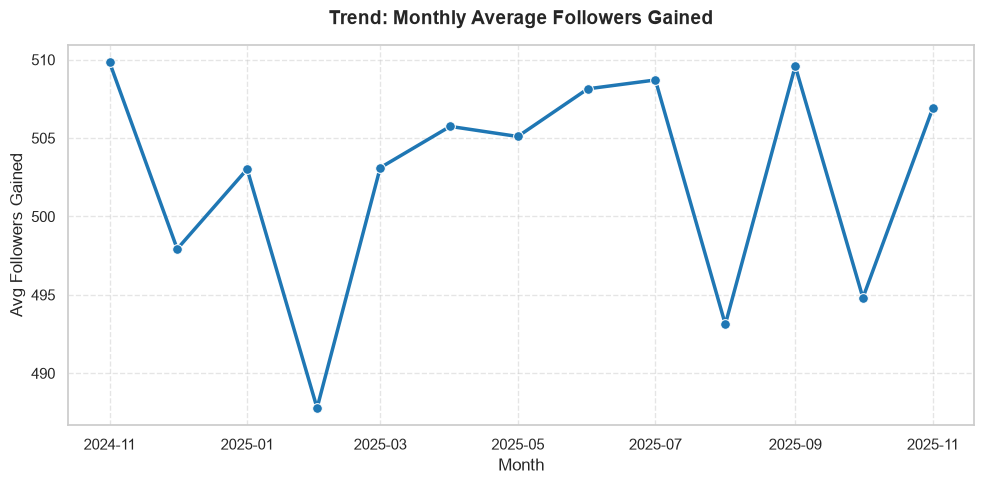

In [23]:
# Prepare monthly average followers gained
df['post_date'] = pd.to_datetime(df['post_date'])
monthly_followers = df.groupby(df['post_date'].dt.to_period('M'))['followers_gained'].mean().reset_index()
monthly_followers['post_date'] = monthly_followers['post_date'].dt.to_timestamp()

# Plot Line Chart
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=monthly_followers,
    x='post_date',
    y='followers_gained',
    marker='o',
    color='#1f77b4',       # Blue line
    linewidth=2.5,
    markersize=7
)

plt.title('Trend: Monthly Average Followers Gained', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Avg Followers Gained', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


Bar Chart (Data: content_category vs Total Posts)

C:\Users\JAYASRI\AppData\Local\Temp\ipykernel_2088\430677361.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


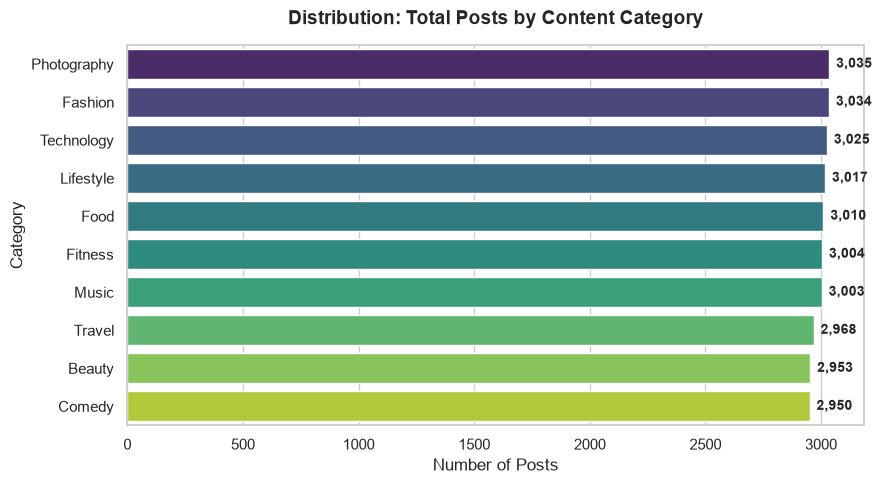

In [24]:
# Count total posts per content category
category_counts = df['content_category'].value_counts().reset_index()
category_counts.columns = ['content_category', 'total_posts']

# Plot Horizontal Bar Chart
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=category_counts,
    y='content_category',
    x='total_posts',
    palette='viridis'
)

# Add exact counts on the bars
for p in ax.patches:
    ax.annotate(
        f"{int(p.get_width()):,}",
        (p.get_width(), p.get_y() + p.get_height() / 2.),
        ha='left', va='center',
        xytext=(5, 0),
        textcoords='offset points',
        fontweight='bold',
        fontsize=10
    )

plt.title('Distribution: Total Posts by Content Category', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Posts', fontsize=12)
plt.ylabel('Category', fontsize=12)
plt.tight_layout()
plt.show()


Scatter Plot for your Instagram Analytics dataset.

A scatter plot compares two numeric variables. In this dataset, Reach vs. Likes has a strong relationship ($r = 0.74$)—showing how higher post reach directly leads to more likes.

We also color-code the points by media_type (Reel, Image, Carousel) to see which format performs best.

Reach vs. Likes (Categorized by Media Type)

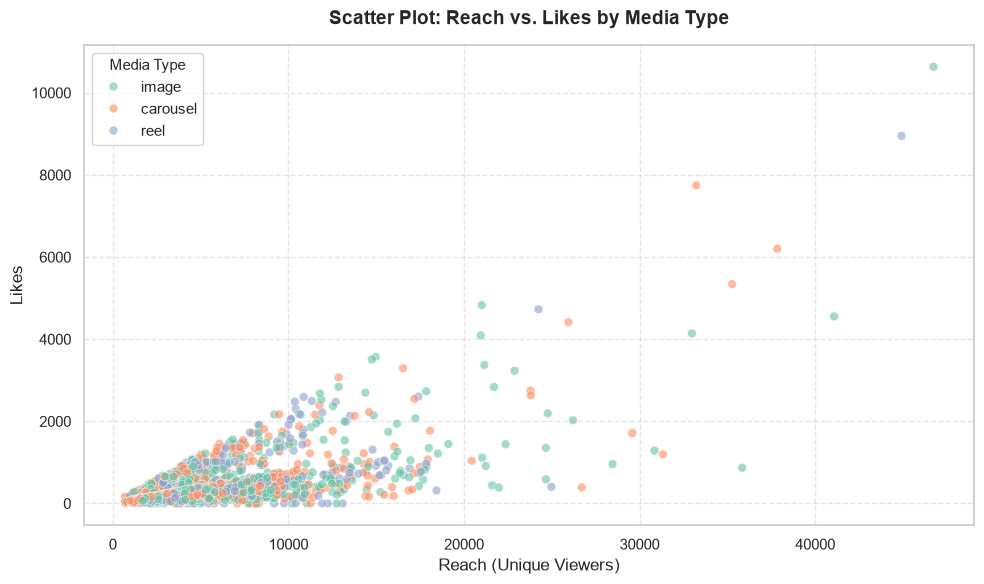

In [17]:
# Sample 1,500 points for a crisp, fast-rendering plot
sample_df = df.sample(n=1500, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=sample_df,
    x='reach',
    y='likes',
    hue='media_type',       # Colors points by Reel, Image, Carousel
    palette='Set2',
    alpha=0.6,              # Transparency to see overlapping points
    s=40                    # Point size
)

plt.title('Scatter Plot: Reach vs. Likes by Media Type', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Reach (Unique Viewers)', fontsize=12)
plt.ylabel('Likes', fontsize=12)
plt.legend(title='Media Type', title_fontsize='11', loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


Scatter Plot with a Regression Trendline

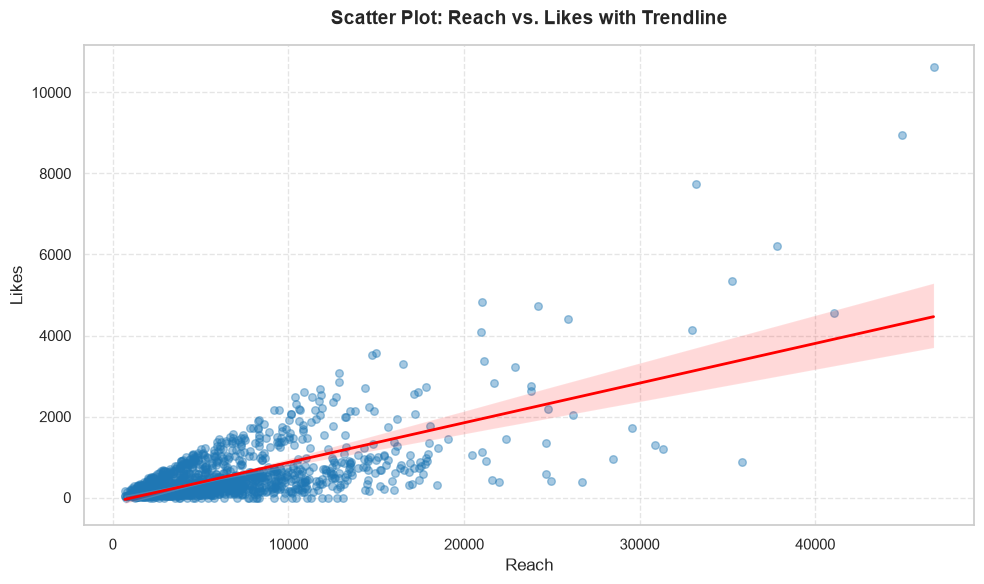

In [18]:
plt.figure(figsize=(10, 6))

# regplot adds a linear regression line automatically
sns.regplot(
    data=sample_df,
    x='reach',
    y='likes',
    scatter_kws={'alpha': 0.4, 'color': '#1f77b4', 's': 30},
    line_kws={'color': 'red', 'linewidth': 2}
)

plt.title('Scatter Plot: Reach vs. Likes with Trendline', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Reach', fontsize=12)
plt.ylabel('Likes', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [15]:
#  Average likes and reach for each content category
df.groupby('content_category')[['likes', 'reach']].mean()

,likes,reach
content_category,,
Beauty,288.440230,6340.979343
Comedy,289.001356,6303.413898
Fashion,296.815425,6347.159855
Fitness,289.139481,6218.894807
Food,287.629900,6248.638538
Lifestyle,285.744448,6261.529997
Music,292.132867,6274.301365
Photography,290.391104,6417.292916
Technology,277.763967,6092.297521


## Final Insights

1. The dataset has about 30,000 posts with no missing values, and a typical post reaches about 4,900 people and gets about 199 likes (median), while the mean is 288 because a few viral posts pull it up.
2. Reach is the strongest driver of likes, but the link is loose: many posts with 20,000+ reach still got under 1,000 likes, so content quality matters as much as visibility.
3. Engagement rate stays near 4% and followers gained stays near 500 per post across the year (488 to 510), so there is no clear growth or seasonal trend.
4. Categories are evenly split at about 3,000 posts each, and image, carousel and reel perform in a similar range, so no category or format is a clear winner.
5. The next step is to compare engagement rate by posting hour, media type, traffic source and call-to-action, since these will show what to post and when.